# DreamPoly

Лексика, эмоции и темы в DreamBank. Сначала возрастные серии Izzy, затем студенческие коллекции мужчин и женщин 1997–1998.

Источник: [DreamBank](https://dreambank.net/), Adam Schneider и G. William Domhoff. Снимок [5 января 2026](https://zenodo.org/records/18159468), CC BY-NC-SA 4.0.

## 1. Библиотеки и папки

In [2]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import re
import tarfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from nrclex import NRCLex
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF
from nltk.stem import SnowballStemmer
from scipy.stats import mannwhitneyu
from IPython.display import display, Markdown

cwd = Path.cwd().resolve()
if (cwd / 'DreamPoly.ipynb').is_file():
    notebooks = cwd
elif (cwd / 'notebooks' / 'DreamPoly.ipynb').is_file():
    notebooks = cwd / 'notebooks'
else:
    raise FileNotFoundError('Запустите ноутбук из корня репозитория или из папки notebooks')

ROOT = notebooks.parent
RAW = notebooks / 'data' / 'raw'
HTML = RAW / 'html'
OUT = notebooks / 'results' / 'DreamPoly'
TABLES = OUT / 'processed'
RESULTS = OUT
FIGURES = OUT / 'figures'
for folder in [RAW, HTML, TABLES, RESULTS, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)
plt.rcParams['font.family'] = 'DejaVu Sans'
print('Корень репозитория:', ROOT)
print('Результаты:', OUT)

Рабочая папка: d:\Projects\Personal\python\dreambank


## 2. Архив

In [3]:
ARCHIVE = RAW / 'dreambank.tar.xz'
EXPECTED_MD5 = 'eb83bcb0828f9c8c248a5052b2ffc798'
if not ARCHIVE.exists():
    request = urllib.request.Request(
        'https://zenodo.org/api/records/18159468',
        headers={'User-Agent': 'DreamPoly educational project'})
    with urllib.request.urlopen(request, timeout=60) as response:
        record = json.load(response)
    file_info = next(f for f in record['files'] if f['key'] == ARCHIVE.name)
    urllib.request.urlretrieve(file_info['links']['self'], ARCHIVE)
assert hashlib.md5(ARCHIVE.read_bytes()).hexdigest() == EXPECTED_MD5

with tarfile.open(ARCHIVE, 'r:xz') as archive:
    for member in archive.getmembers():
        name = Path(member.name)
        if member.isfile() and not name.is_absolute() and '..' not in name.parts:
            target = (HTML / name).resolve()
            if HTML.resolve() in target.parents:
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(archive.extractfile(member).read())
print('HTML-файлов:', len(list(HTML.rglob('*.html'))))

HTML-файлов: 289


## 3. Парсинг HTML

В `info.html` метаданные серии, в `dreams.html` тексты. Запись начинается с `#номера` и заканчивается числом слов. Возраст и даты в заголовке остаются как в источнике.

In [5]:
def clean(text):
    return re.sub(r'\s+', ' ', text).strip()

def read_series(folder):
    soup = BeautifulSoup((folder / 'info.html').read_bytes(), 'html.parser', from_encoding='windows-1252')
    labels = {'Dream series:': 'series_title', 'Number of dreams:': 'reported_count',
              'Year:': 'series_years_raw', 'Sex of the dreamer(s):': 'dreamer_sex_raw'}
    row = {'series_id': folder.name, 'language': 'de' if folder.name.endswith('.de') else 'en'}
    for bold in soup.find_all('b'):
        label = clean(bold.get_text(' ', strip=True))
        if label in labels:
            pieces = []
            for sibling in bold.next_siblings:
                if getattr(sibling, 'name', None) == 'br':
                    break
                pieces.append(sibling.get_text(' ', strip=True)
                              if getattr(sibling, 'name', None) else str(sibling))
            row[labels[label]] = clean(' '.join(pieces))
    row['reported_count'] = int(row['reported_count'].replace(',', ''))
    return row

def read_dreams(folder, series):
    soup = BeautifulSoup((folder / 'dreams.html').read_bytes(), 'html.parser', from_encoding='windows-1252')
    rows = []
    for span in soup.find_all('span'):
        header_parts = []
        for child in span.contents:
            if getattr(child, 'name', None) == 'br':
                break
            header_parts.append(child.get_text(' ', strip=True)
                                if getattr(child, 'name', None) else str(child))
        header = clean(' '.join(header_parts))
        if not header.startswith('#'):
            continue
        number, metadata = re.match(r'^#(\S+)(?:\s+\((.*)\))?$', header).groups()
        body = clean(span.get_text(' ', strip=True))[len(header):].strip()
        word_count = re.search(r'\(([\d,]+)\s+words?\)\s*$', body, re.I)
        text = clean(body[:word_count.start()])
        rows.append({
            'dream_id': f"{folder.name}:{number}", 'series_id': folder.name,
            'dream_number_raw': number, 'header_metadata_raw': metadata or '',
            'text': text, 'word_count_reported': int(word_count[1].replace(',', '')),
            'language': series['language'], 'dreamer_sex_raw': series['dreamer_sex_raw'],
            'series_years_raw': series['series_years_raw'],
            'source_file': (folder / 'dreams.html').relative_to(ROOT).as_posix()})
    return rows

In [6]:
series_rows, dream_rows = [], []
for folder in sorted(HTML.iterdir()):
    if folder.is_dir() and (folder / 'info.html').exists():
        series = read_series(folder)
        records = read_dreams(folder, series)
        series['parsed_count'] = len(records)
        series_rows.append(series)
        dream_rows.extend(records)
series_df = pd.DataFrame(series_rows)
dreams = pd.DataFrame(dream_rows)
display(dreams[['dream_id', 'text', 'language']].head())
print(f'Серий: {len(series_df)}, записей: {len(dreams):,}')
print(f'Количество записей на английском: {len(dreams[dreams['language']=='en'])}')

,dream_id,text,language
0,alta:1,"The one at the Meads's house, where it's bigge...",en
1,alta:2,I'm at a family reunion in a large fine house ...,en
2,alta:3,I watch a plane fly past and shortly realize i...,en
3,alta:4,Me pulling the green leaves and berries off so...,en
4,alta:5,I'm in a room that reminds me of (but definite...,en


Серий: 96, записей: 45,058
Количество записей на английском: 38128


## 4. Проверки

Пустые тексты и повторы идентификаторов. Сравнения по возрасту идут по сериям Izzy, не по таблице без дублей.

In [7]:
assert dreams['text'].str.len().gt(0).all(), 'Есть пустой текст'
assert dreams['dream_id'].is_unique, 'Повторился идентификатор'
unique_dreams = dreams.drop_duplicates('text').copy()
for name, table in [('series_simple', series_df), ('dreams_simple', dreams),
                    ('dreams_unique_simple', unique_dreams)]:
    table.to_csv(TABLES / f'{name}.csv', index=False, encoding='utf-8-sig')
    table.to_parquet(TABLES / f'{name}.parquet', index=False)
display(series_df.loc[series_df['reported_count'] != series_df['parsed_count'],
                      ['series_id', 'reported_count', 'parsed_count']])
print('Уникальных точных текстов:', len(unique_dreams))

,series_id,reported_count,parsed_count
3,b,3116,3114
17,college-f,160,159
50,kenneth,2022,2021
91,vonuslar.de,6100,6094


Уникальных точных текстов: 34838


В снимке 45 058 записей из 96 серий, 34 838 уникальных точных текстов. В четырёх сериях заявленное число не совпадает с числом записей.

## 5. Izzy

Один автор, разные возрастные серии. Возраст не отделён от эпохи и длины записей. Частоты NRC — на 1000 токенов сна.

In [8]:
AGE_GROUPS = {'izzy12': '12', 'izzy13': '13', 'izzy14': '14', 'izzy15': '15',
              'izzy16': '16', 'izzy17': '17', 'izzy18_21': '18–21', 'izzy22_25': '22–25'}
AGES = list(AGE_GROUPS.values())
izzy = dreams[dreams['series_id'].isin(AGE_GROUPS)].copy().reset_index(drop=True)
izzy['age_group'] = izzy['series_id'].map(AGE_GROUPS)
izzy['age_group'] = pd.Categorical(izzy['age_group'], categories=AGES, ordered=True)
display(izzy.groupby('age_group', observed=True).size().rename('Снов').to_frame())

EMOTIONS = ['anger', 'fear', 'anticipation', 'trust', 'surprise', 'sadness', 'disgust', 'joy']
vader, nrc = SentimentIntensityAnalyzer(), NRCLex()

def tokens(text):
    return re.findall(r"[A-Za-z]+(?:['’][A-Za-z]+)?", text.lower())

def features(text):
    words = tokens(text)
    nrc.load_token_list(words)
    result = {'token_count': len(words), 'vader': vader.polarity_scores(text)['compound']}
    for emotion in EMOTIONS:
        result[emotion] = nrc.raw_emotion_scores.get(emotion, 0) * 1000 / max(len(words), 1)
    result['mattr_50'] = (np.mean([len(set(words[i:i+50])) / 50
                                for i in range(len(words)-49)]) if len(words) >= 50 else np.nan)
    return result

izzy = pd.concat([izzy, pd.DataFrame([features(t) for t in izzy['text']])], axis=1)
age_means = izzy.groupby('age_group', observed=True)[
    ['token_count', 'mattr_50', 'vader'] + EMOTIONS].mean()
izzy.to_parquet(RESULTS / 'izzy_per_dream.parquet', index=False)
age_means.to_csv(RESULTS / 'izzy_by_age.csv', encoding='utf-8-sig')

,Снов
age_group,
12,52
13,167
14,249
15,539
16,845
17,741
18–21,1359
22–25,377


## 6. Эмоции и тональность

Частота слов NRC и оценка VADER от −1 до +1.

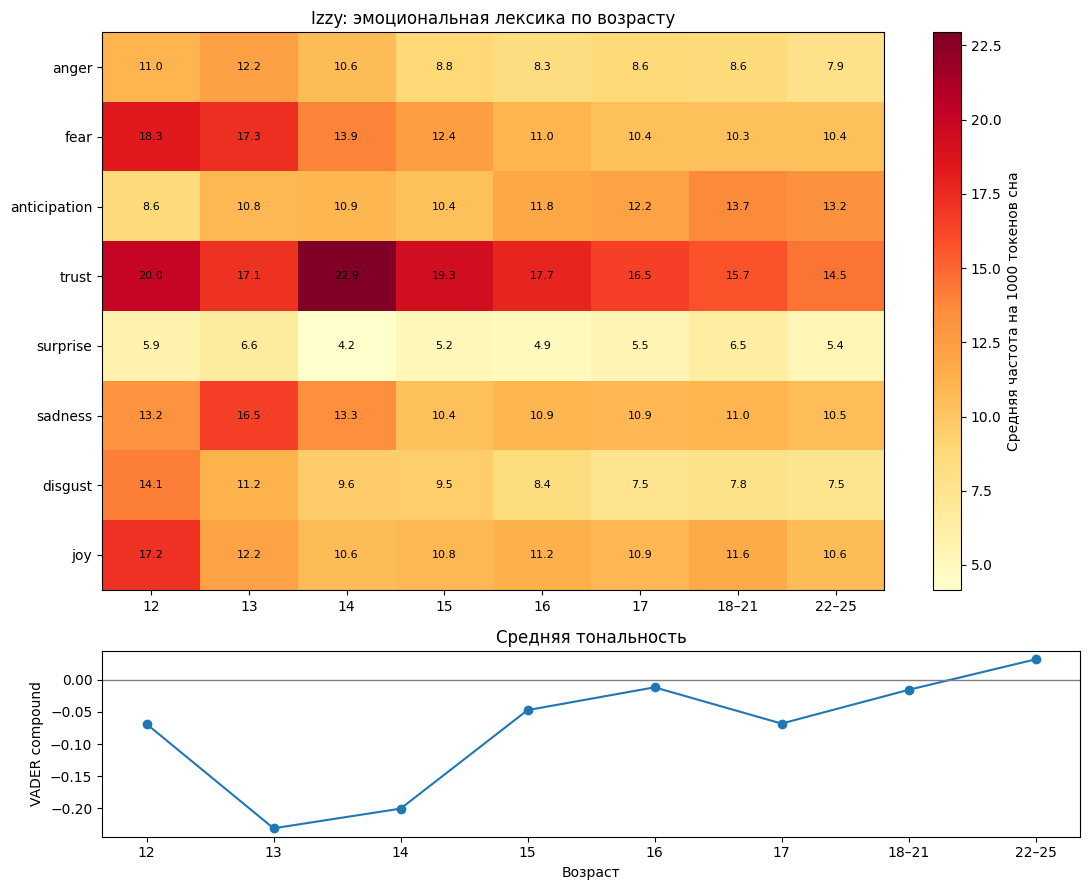

**Вывод:** частота лексики страха меняется с 18.3 до 10.4 на 1000 токенов. Тональность поздних записей в среднем выше ранних. Это наблюдение по одному дневнику, не доказательство влияния возраста.

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(11, 9), gridspec_kw={'height_ratios': [3, 1]})
heat = age_means[EMOTIONS].T.to_numpy()
image = axes[0].imshow(heat, aspect='auto', cmap='YlOrRd')
axes[0].set_xticks(range(len(AGES)), AGES)
axes[0].set_yticks(range(len(EMOTIONS)), EMOTIONS)
axes[0].set_title('Izzy: эмоциональная лексика по возрасту')
for row in range(len(EMOTIONS)):
    for col in range(len(AGES)):
        axes[0].text(col, row, f'{heat[row, col]:.1f}', ha='center', va='center', fontsize=8)
fig.colorbar(image, ax=axes[0], label='Средняя частота на 1000 токенов сна')
axes[1].plot(AGES, age_means['vader'], marker='o')
axes[1].axhline(0, color='gray', linewidth=1)
axes[1].set(xlabel='Возраст', ylabel='VADER compound', title='Средняя тональность')
fig.tight_layout()
fig.savefig(FIGURES / '01_emotions_by_age.png', dpi=160, bbox_inches='tight')
plt.show()
display(Markdown(f"**Вывод:** частота лексики страха меняется с {age_means['fear'].iloc[0]:.1f} "
                 f"до {age_means['fear'].iloc[-1]:.1f} на 1000 токенов. "
                 'Тональность поздних записей в среднем выше ранних. '
                 'Это наблюдение по одному дневнику, не доказательство влияния возраста.'))

## 7. Длина и словарь

MATTR-50 — доля разных слов в окнах по 50 токенов. Тексты короче 50 слов в метрику не входят.

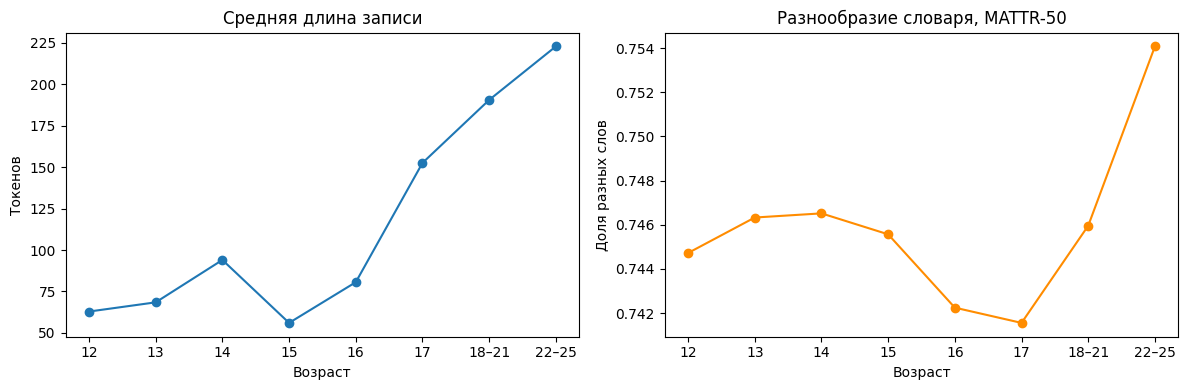

age_group
12         27
13         95
14        185
15        235
16        483
17        589
18–21    1222
22–25     351
Name: Записей ≥ 50 токенов, dtype: int64

**Вывод:** средняя длина возрастает с 63 до 223 токенов. Изменение MATTR значительно скромнее; длина и стиль рассказа могут объяснять часть возрастных различий.

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(AGES, age_means['token_count'], marker='o')
axes[0].set(title='Средняя длина записи', xlabel='Возраст', ylabel='Токенов')
axes[1].plot(AGES, age_means['mattr_50'], marker='o', color='darkorange')
axes[1].set(title='Разнообразие словаря, MATTR-50', xlabel='Возраст', ylabel='Доля разных слов')
fig.tight_layout()
fig.savefig(FIGURES / '02_length_vocabulary.png', dpi=160, bbox_inches='tight')
plt.show()
display(izzy.groupby('age_group', observed=True)['mattr_50'].count().rename('Записей ≥ 50 токенов'))
display(Markdown(f"**Вывод:** средняя длина возрастает с {age_means['token_count'].iloc[0]:.0f} "
                 f"до {age_means['token_count'].iloc[-1]:.0f} токенов. "
                 'Изменение MATTR значительно скромнее; длина и стиль рассказа '
                 'могут объяснять часть возрастных различий.'))

## 8. Темы

TF–IDF и NMF, восемь компонентов. Названия даны по ключевым словам. Веса нормированы по строке и не равны доле снов на тему.

In [16]:
vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1, 2),
                            min_df=10, max_df=0.85, max_features=6000, sublinear_tf=True)
izzy_topics = izzy.sort_values(['series_id', 'dream_number_raw']).reset_index(drop=True)
matrix = vectorizer.fit_transform(izzy_topics['text'])
model = NMF(n_components=8, init='nndsvda', random_state=42, max_iter=700)
weights = model.fit_transform(matrix)
shares = weights / np.maximum(weights.sum(axis=1, keepdims=True), 1e-12)
terms = vectorizer.get_feature_names_out()
labels = ['Диалоги', 'Школа', 'Воспоминание', 'Семья и дом',
          'Фильмы', 'Люди и действия', 'Комнаты и здания', 'Повторяющиеся имена']
topic_terms = pd.DataFrame({'Компонент': labels,
                           'Ключевые слова': [', '.join(terms[c.argsort()[-12:][::-1]])
                                             for c in model.components_]})
display(topic_terms)
topic_terms.to_csv(RESULTS / 'topic_terms.csv', index=False, encoding='utf-8-sig')
topic_table = pd.DataFrame(shares, columns=labels)
topic_table['age_group'] = izzy_topics['age_group']
topic_by_age = topic_table.groupby('age_group', observed=True)[labels].mean()
topic_by_age.to_csv(RESULTS / 'topics_by_age.csv', encoding='utf-8-sig')

,Компонент,Ключевые слова
0,Диалоги,"said, like, didn, asked, know, saying, just, t..."
1,Школа,"calvin, school, dmitri, samantha, evelyn, elij..."
2,Воспоминание,"remember, don remember, don, dream, properly, ..."
3,Семья и дом,"ezra, mom, dad, home, car, mom ezra, dad ezra,..."
4,Фильмы,"watching, movie, watching movie, guy, tv, girl..."
5,Люди и действия,"guy, people, got, place, thing, girl, went, ca..."
6,Комнаты и здания,"room, house, door, bed, went, came, outside, r..."
7,Повторяющиеся имена,"eugene, darius, jeremiah, bradley, thinking, s..."


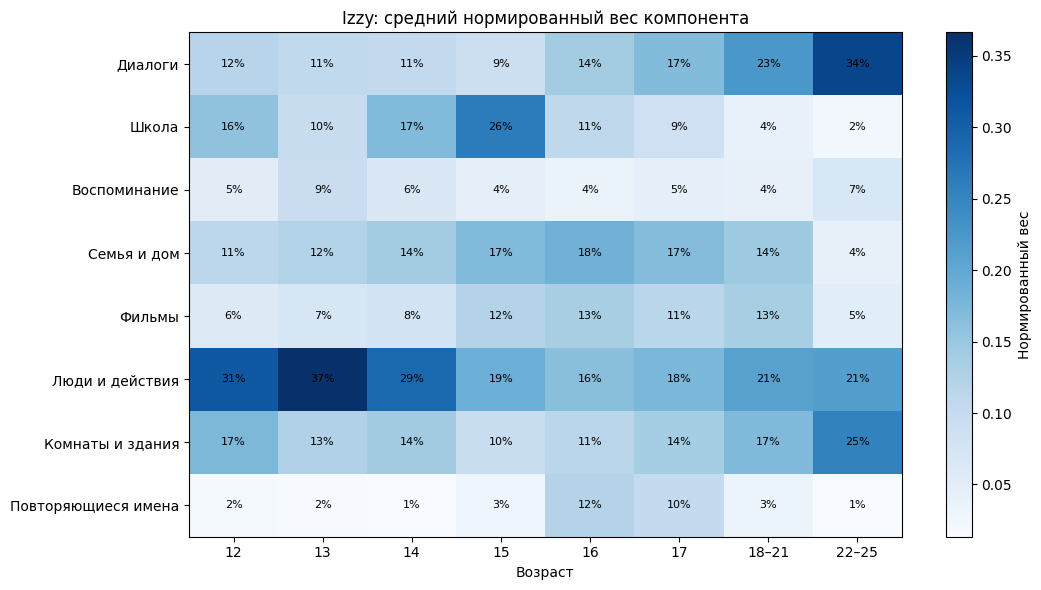

**Вывод:** сравниваем изменение словарных компонентов по возрасту. Снижение веса школы согласуется с переходом к другим жизненным периодам, но NMF может реагировать также на имена и стиль дневника. Названия проверяем по таблице ключевых слов выше.

In [17]:
fig, ax = plt.subplots(figsize=(11, 6))
heat = topic_by_age.T.to_numpy()
image = ax.imshow(heat, aspect='auto', cmap='Blues')
ax.set_xticks(range(len(AGES)), AGES)
ax.set_yticks(range(len(labels)), labels)
ax.set(xlabel='Возраст', title='Izzy: средний нормированный вес компонента')
for row in range(len(labels)):
    for col in range(len(AGES)):
        ax.text(col, row, f'{heat[row, col]:.0%}', ha='center', va='center', fontsize=8)
fig.colorbar(image, ax=ax, label='Нормированный вес')
fig.tight_layout()
fig.savefig(FIGURES / '03_topics_by_age.png', dpi=160, bbox_inches='tight')
plt.show()
display(Markdown('**Вывод:** сравниваем изменение словарных компонентов по возрасту. '
                 'Снижение веса школы согласуется с переходом к другим жизненным периодам, '
                 'но NMF может реагировать также на имена и стиль дневника. '
                 'Названия проверяем по таблице ключевых слов выше.'))

## 9. Пол

Серии `college-f` и `college-m`: студенты одного периода. Mann–Whitney по записям, поправка Benjamini–Hochberg.

In [18]:
GROUPS = {'college-f': 'Женщины', 'college-m': 'Мужчины'}
college = dreams[dreams['series_id'].isin(GROUPS)].copy().reset_index(drop=True)
college['group'] = college['series_id'].map(GROUPS)
college = pd.concat([college, pd.DataFrame([features(t) for t in college['text']])], axis=1)
display(college.groupby('group').size().rename('Число записей'))
metrics = ['token_count', 'mattr_50', 'vader'] + EMOTIONS
gender_means = college.groupby('group')[metrics].mean()
comparison = []
for metric in metrics:
    female = college.loc[college['group'] == 'Женщины', metric].dropna()
    male = college.loc[college['group'] == 'Мужчины', metric].dropna()
    test = mannwhitneyu(female, male, alternative='two-sided')
    comparison.append({'metric': metric, 'female_mean': female.mean(), 'male_mean': male.mean(),
                       'p': test.pvalue, 'cliffs_delta': 2*test.statistic/(len(female)*len(male))-1})
comparison = pd.DataFrame(comparison).sort_values('p').reset_index(drop=True)
adjusted = comparison['p'].to_numpy() * len(metrics) / np.arange(1, len(metrics)+1)
comparison['p_adjusted'] = np.minimum.accumulate(adjusted[::-1])[::-1].clip(0, 1)
display(comparison.round(4))
comparison.to_csv(RESULTS / 'gender_comparison.csv', index=False, encoding='utf-8-sig')
college.to_parquet(RESULTS / 'college_per_dream.parquet', index=False)

group
Женщины    159
Мужчины    160
Name: Число записей, dtype: int64

,metric,female_mean,male_mean,p,cliffs_delta,p_adjusted
0,token_count,139.5094,115.6375,0.0020,0.1997,0.0225
1,disgust,7.4394,5.9506,0.0212,0.1380,0.1164
2,anger,8.7234,10.2935,0.0979,-0.1018,0.3083
3,mattr_50,0.7478,0.7411,0.1121,0.1078,0.3083
4,sadness,14.7478,13.0583,0.4364,0.0496,0.7403
5,trust,21.7540,24.6478,0.4992,-0.0437,0.7403
6,vader,0.1848,0.2366,0.5740,-0.0364,0.7403
7,anticipation,18.6963,21.0587,0.6197,-0.0321,0.7403
8,fear,11.4798,13.2283,0.6396,-0.0294,0.7403
9,surprise,9.2941,11.1961,0.7037,-0.0239,0.7403


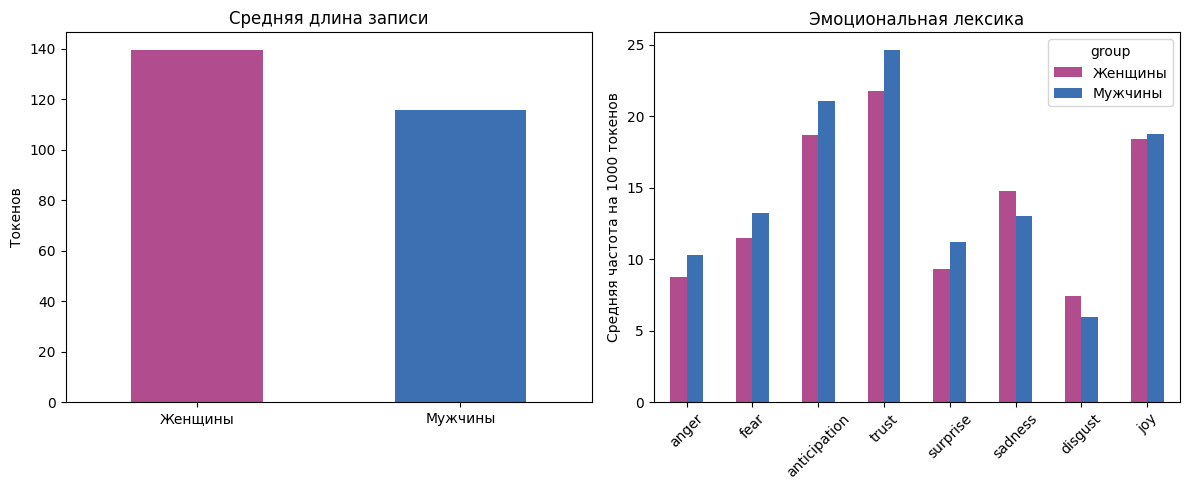

**Вывод:** средняя длина женских записей — 139.5, мужских — 115.6 токена. Различия эмоциональных оценок после поправки неубедительны. Результат относится к этим коллекциям, не ко всем людям.

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
gender_means['token_count'].reindex(['Женщины', 'Мужчины']).plot.bar(
    ax=axes[0], color=['#b14d8e', '#3d70b2'], rot=0)
axes[0].set(title='Средняя длина записи', ylabel='Токенов', xlabel='')
gender_means[EMOTIONS].T[['Женщины', 'Мужчины']].plot.bar(
    ax=axes[1], color=['#b14d8e', '#3d70b2'], rot=45)
axes[1].set(title='Эмоциональная лексика', ylabel='Средняя частота на 1000 токенов', xlabel='')
fig.tight_layout()
fig.savefig(FIGURES / '04_gender_metrics.png', dpi=160, bbox_inches='tight')
plt.show()
display(Markdown(f"**Вывод:** средняя длина женских записей — {gender_means.loc['Женщины', 'token_count']:.1f}, "
                 f"мужских — {gender_means.loc['Мужчины', 'token_count']:.1f} токена. "
                 'Различия эмоциональных оценок после поправки неубедительны. '
                 'Результат относится к этим коллекциям, не ко всем людям.'))

## 10. Слова по полу

Без служебных слов и слов о сне. Формы сведены стеммером Snowball. Частота на 10 000 содержательных токенов, сортировка по разности.

In [20]:
stop_words = set(ENGLISH_STOP_WORDS) | {
    'im', 'ive', 'id', 'dont', 'didnt', 'doesnt', 'wasnt', 'werent', 'isnt',
    'arent', 'couldnt', 'wouldnt', 'really', 'dream', 'dreamed', 'dreamt'}
stemmer = SnowballStemmer('english')
counts, forms, totals = {}, {}, {}
for group in ['Женщины', 'Мужчины']:
    counts[group], forms[group] = Counter(), {}
    for text in college.loc[college['group'] == group, 'text']:
        for word in tokens(text):
            if word in stop_words or len(word) < 3:
                continue
            stem = stemmer.stem(word)
            counts[group][stem] += 1
            forms[group].setdefault(stem, Counter())[word] += 1
    totals[group] = sum(counts[group].values())
rows = []
for stem in sorted(set(counts['Женщины']) | set(counts['Мужчины'])):
    f, m = counts['Женщины'][stem], counts['Мужчины'][stem]
    if f+m < 10:
        continue
    spellings = forms['Женщины'].get(stem, Counter()) + forms['Мужчины'].get(stem, Counter())
    rows.append({'word': spellings.most_common(1)[0][0], 'female_count': f, 'male_count': m,
                 'female': f*10000/totals['Женщины'], 'male': m*10000/totals['Мужчины']})
word_table = pd.DataFrame(rows)
word_table['shared'] = word_table[['female', 'male']].min(axis=1)
word_table['difference'] = word_table['female']-word_table['male']
word_table.to_csv(RESULTS / 'words_by_gender.csv', index=False, encoding='utf-8-sig')
common = word_table.nlargest(15, 'shared')
female_words = word_table.nlargest(12, 'difference')
male_words = word_table.nsmallest(12, 'difference')
display(common[['word', 'female_count', 'male_count', 'female', 'male']].round(2))

,word,female_count,male_count,female,male
109,friend,115,78,141.84,115.61
182,looked,94,75,115.93,111.16
175,like,94,68,115.93,100.79
238,remember,66,70,81.40,103.75
318,went,104,54,128.27,80.04
41,car,64,59,78.93,87.45
118,got,62,54,76.47,80.04
309,walked,69,47,85.10,69.66
155,just,62,46,76.47,68.18
321,woke,55,59,67.83,87.45


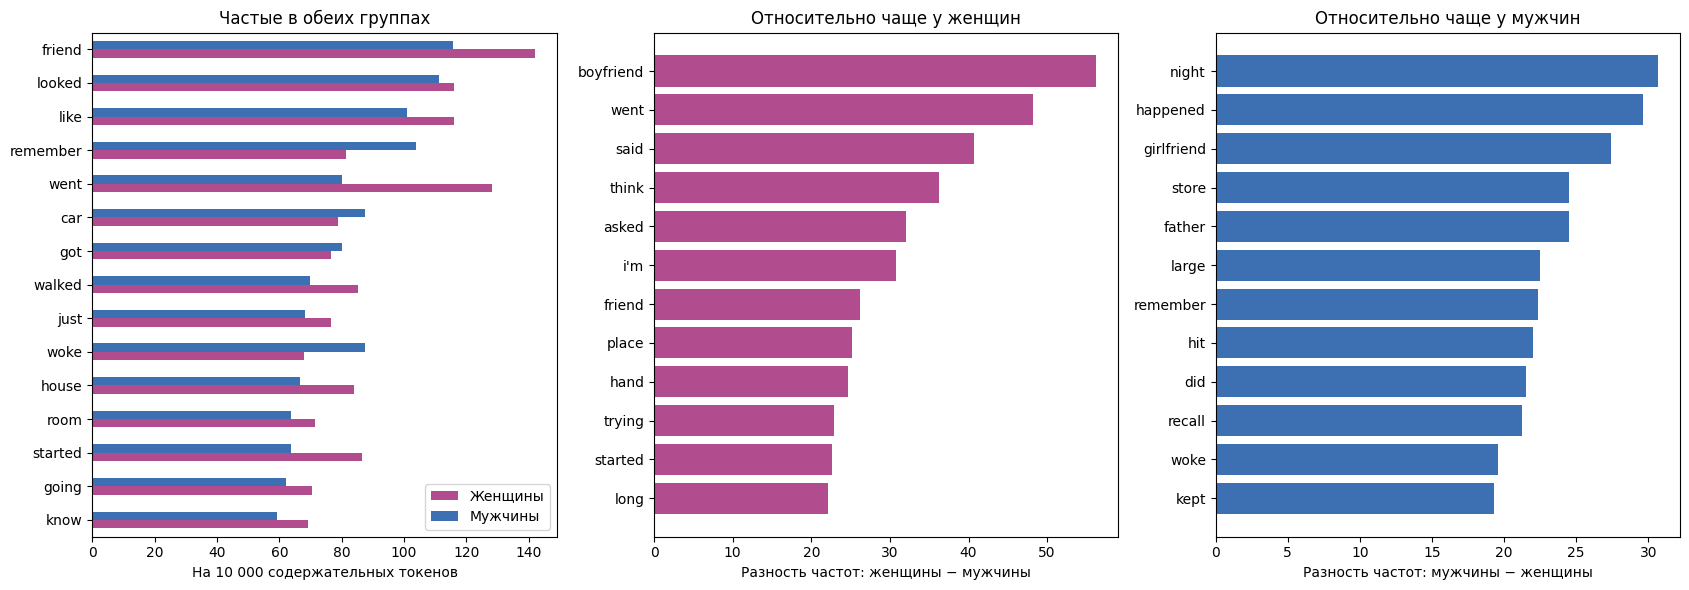

**Вывод:** часто встречаются слова о друзьях, движении, доме и воспоминании. Различительные слова — кандидаты для проверки на других выборках: отдельный длинный рассказ тоже может влиять на частоту. Показанная разница не доказывает различий между полами вообще.

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
common.set_index('word')[['female', 'male']].iloc[::-1].plot.barh(
    ax=axes[0], color=['#b14d8e', '#3d70b2'])
axes[0].legend(['Женщины', 'Мужчины'])
axes[0].set(title='Частые в обеих группах', xlabel='На 10 000 содержательных токенов', ylabel='')
axes[1].barh(female_words['word'].iloc[::-1], female_words['difference'].iloc[::-1], color='#b14d8e')
axes[1].set(title='Относительно чаще у женщин', xlabel='Разность частот: женщины − мужчины')
axes[2].barh(male_words['word'].iloc[::-1], -male_words['difference'].iloc[::-1], color='#3d70b2')
axes[2].set(title='Относительно чаще у мужчин', xlabel='Разность частот: мужчины − женщины')
fig.tight_layout()
fig.savefig(FIGURES / '05_words_by_gender.png', dpi=160, bbox_inches='tight')
plt.show()
display(Markdown('**Вывод:** часто встречаются слова о друзьях, движении, доме '
                 'и воспоминании. Различительные слова — кандидаты для проверки '
                 'на других выборках: отдельный длинный рассказ тоже может влиять '
                 'на частоту. Показанная разница не доказывает различий между полами вообще.'))

## Ограничения

Словарные оценки не разбирают сюжет. NMF реагирует на имена. Несколько записей одного автора зависимы. Возраст, эпоха и стиль меняются вместе.

Методы: [VADER](https://github.com/cjhutto/vaderSentiment), [NRCLex](https://pypi.org/project/NRCLex/), [NMF](https://scikit-learn.org/stable/modules/decomposition.html#nmf). Domhoff & Schneider (2008), [Studying dream content using the archive and search engine on DreamBank.net](https://doi.org/10.1016/j.concog.2008.06.010).